In [ ]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import (
    brier_score_loss,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix
)
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [ ]:

dfraw = pd.read_csv('gss2024_onet_cleaned_v2.csv')

In [ ]:
#set prediction varible to satjob
y = (dfraw['satjob'] >= 3).astype(int)

In [ ]:
#seperate baseline features from prestige
base_features_A0 = [
    'age', 'hrs1', 'weekswrk', 'childs', 'realrinc',
    'educ', 'wrkstat', 'wrkslf', 'sex',
    'race', 'hispanic', 'born', 'marital', 'region', 'union1'
]
features_A1 = base_features_A0 + ['prestg10']

#for future model training on non-baseline features
features_B = features_A1 + [
    'Achievement', 'Independence', 'Recognition',
    'Relationships', 'Support', 'Working Conditions', 'job_zone'
]

In [ ]:
#create a working copy of the dataset using only Model A1
X = dfraw[features_A1].copy()

In [ ]:
#apply log transformation to real income after clipping values at zero
if 'realrinc' in X.columns:
    X['realrinc'] = np.log1p(X['realrinc'].clip(lower=0))

In [ ]:
#identify and store lists of numeric and categorical column names from the dataset
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

In [ ]:
#create preprocessing pipeline to impute missing numeric values with the median and standardize features
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])

#create a preprocessing pipeline to fill missing categorical values with a constant and one-hot encode features
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])
#combine the numeric and categorical transformaton pipelnes into a single preprocessing column transformer
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

In [ ]:
#build ML pipeline
logistic_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegressionCV(
        Cs=10,
        cv=3,
        scoring='roc_auc',
        penalty='l2',
        solver='lbfgs',
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

In [ ]:
#intialize repeated strtified cross-validation
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
#lists to store out-of-fold predictions and true labels
oof_preds = []
oof_true = []

In [ ]:
#execute cross validation training and evaluation loop to generate and store pooled out-of-fold predictions
for train_idx, test_idx in rskf.split(X, y):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    logistic_pipeline.fit(X_train, y_train)
    preds = logistic_pipeline.predict_proba(X_test)[:, 1]

    oof_preds.extend(preds)
    oof_true.extend(y_test)

oof_preds = np.array(oof_preds)
oof_true = np.array(oof_true)

In [ ]:
#print accuracy metrics of
final_roc_auc = roc_auc_score(oof_true, oof_preds)
final_pr_auc = average_precision_score(oof_true, oof_preds)
final_brier = brier_score_loss(oof_true, oof_preds)

print(f"Pooled OOF ROC-AUC: {final_roc_auc:.4f}")
print(f"Pooled OOF PR-AUC: {final_pr_auc:.4f}")
print(f"Pooled OOF Brier Score: {final_brier:.4f}")

Pooled OOF ROC-AUC: 0.5934
Pooled OOF PR-AUC: 0.2004
Pooled OOF Brier Score: 0.2463


In [ ]:
#repeat with prestige feature


#without ONET metrics
X_A0 = dfraw[base_features_A0].copy()

# 2. Log-transform income
if 'realrinc' in X_A0.columns:
    X_A0['realrinc'] = np.log1p(X_A0['realrinc'].clip(lower=0))

# 3. Re-extract numeric and categorical columns for A0
numeric_cols_A0 = X_A0.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols_A0 = X_A0.select_dtypes(include=['object', 'category']).columns.tolist()

# 4. Re-define the preprocessor and pipeline specifically for A0
numeric_transformer_A0 = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])

categorical_transformer_A0 = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor_A0 = ColumnTransformer(transformers=[
    ('num', numeric_transformer_A0, numeric_cols_A0),
    ('cat', categorical_transformer_A0, categorical_cols_A0)
])

logistic_pipeline_A0 = Pipeline(steps=[
    ('preprocessor', preprocessor_A0),
    ('classifier', LogisticRegressionCV(
        Cs=10, cv=3, scoring='roc_auc', penalty='l2',
        solver='lbfgs', class_weight='balanced', max_iter=1000, random_state=42
    ))
])

# 5. Run the Cross-Validation loop for A0
oof_preds_A0 = []
oof_true_A0 = []

for train_idx, test_idx in rskf.split(X_A0, y):
    X_train, X_test = X_A0.iloc[train_idx], X_A0.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    logistic_pipeline_A0.fit(X_train, y_train)
    preds = logistic_pipeline_A0.predict_proba(X_test)[:, 1]

    oof_preds_A0.extend(preds)
    oof_true_A0.extend(y_test)

oof_preds_A0 = np.array(oof_preds_A0)
oof_true_A0 = np.array(oof_true_A0)

print(f"A0 Pooled OOF ROC-AUC: {roc_auc_score(oof_true_A0, oof_preds_A0):.4f}")
print(f"A0 Pooled OOF PR-AUC: {average_precision_score(oof_true_A0, oof_preds_A0):.4f}")
print(f"A0 Pooled OOF Brier Score: {brier_score_loss(oof_true_A0, oof_preds_A0):.4f}")

A0 Pooled OOF ROC-AUC: 0.5909
A0 Pooled OOF PR-AUC: 0.1973
A0 Pooled OOF Brier Score: 0.2460


In [ ]:
#define and execute paired bootstrap function to calculate the ROC-AUC performance difference and its 95% confidence interval
def paired_bootstrap_auc_diff(y_true, preds_a0, preds_a1, n_bootstraps=2000, random_state=42):
    np.random.seed(random_state)
    n = len(y_true)
    diffs = []

    base_auc_diff = roc_auc_score(y_true, preds_a1) - roc_auc_score(y_true, preds_a0)

    for _ in range(n_bootstraps):
        indices = np.random.choice(n, size=n, replace=True)
        if len(np.unique(y_true[indices])) < 2:
            continue

        auc_a0 = roc_auc_score(y_true[indices], preds_a0[indices])
        auc_a1 = roc_auc_score(y_true[indices], preds_a1[indices])
        diffs.append(auc_a1 - auc_a0)

    ci_lower = np.percentile(diffs, 2.5)
    ci_upper = np.percentile(diffs, 97.5)

    return base_auc_diff, ci_lower, ci_upper

auc_diff, ci_low, ci_high = paired_bootstrap_auc_diff(oof_true_A0, oof_preds_A0, oof_preds)

print(f"ROC-AUC Difference (A1 - A0): {auc_diff:.4f}")
print(f"95% Bootstrap Confidence Interval: [{ci_low:.4f}, {ci_high:.4f}]")

ROC-AUC Difference (A1 - A0): 0.0025
95% Bootstrap Confidence Interval: [-0.0036, 0.0086]


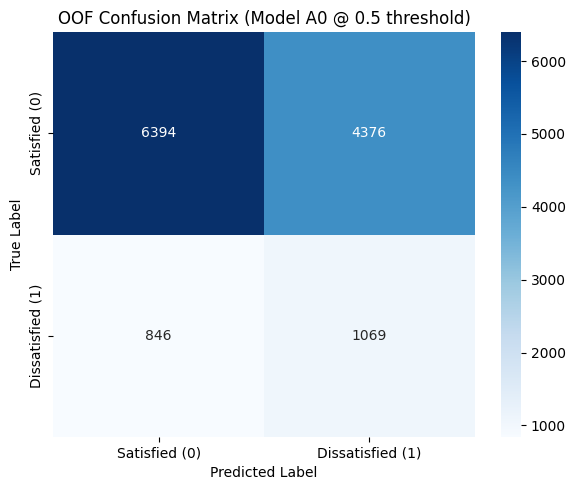

In [ ]:
#plot confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(oof_true_A0, (oof_preds_A0 >= 0.5).astype(int))

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Satisfied (0)', 'Dissatisfied (1)'],
            yticklabels=['Satisfied (0)', 'Dissatisfied (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('OOF Confusion Matrix (Model A0 @ 0.5 threshold)')
plt.tight_layout()
plt.show()

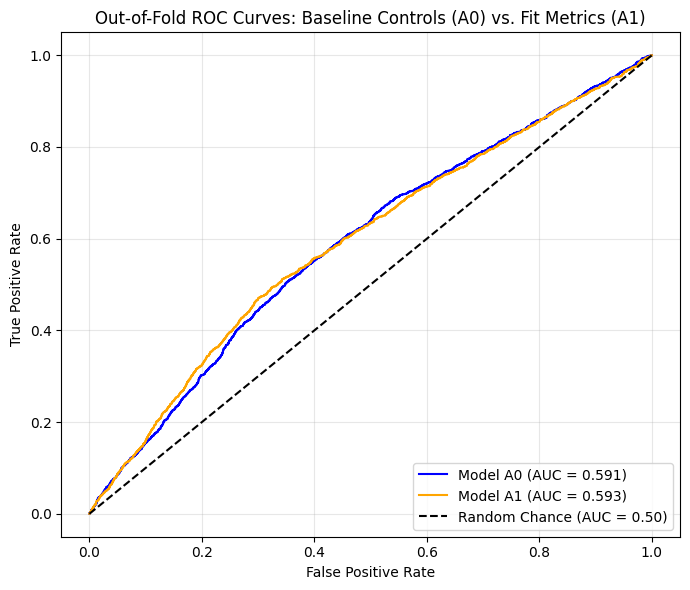

In [ ]:
#plot curves
from sklearn.metrics import roc_curve

fpr_a0, tpr_a0, _ = roc_curve(oof_true_A0, oof_preds_A0)
fpr_a1, tpr_a1, _ = roc_curve(oof_true, oof_preds)

plt.figure(figsize=(7, 6))
plt.plot(fpr_a0, tpr_a0, label=f'Model A0 (AUC = {roc_auc_score(oof_true_A0, oof_preds_A0):.3f})', color='blue')
plt.plot(fpr_a1, tpr_a1, label=f'Model A1 (AUC = {roc_auc_score(oof_true, oof_preds):.3f})', color='orange')
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance (AUC = 0.50)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Out-of-Fold ROC Curves: Baseline Controls (A0) vs. Fit Metrics (A1)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

/tmp/ipykernel_4835/2793082538.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_coefs, x='Coefficient', y='Feature', palette='vlag')


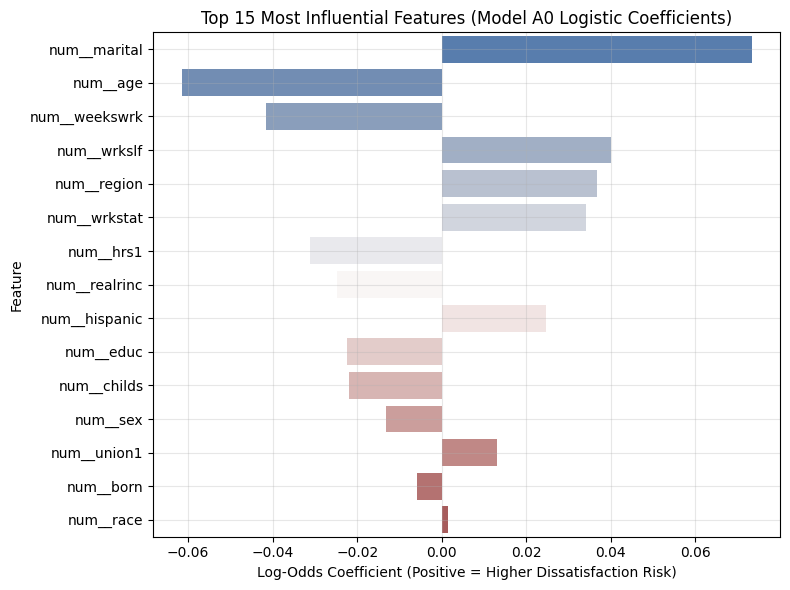

In [ ]:
#extract model coefficients, rank top 15 features by magnitude and plot their log-odds effects
feature_names = logistic_pipeline_A0.named_steps['preprocessor'].get_feature_names_out()
coefficients = logistic_pipeline_A0.named_steps['classifier'].coef_[0]

coef_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefficients})
coef_df['Abs_Coef'] = coef_df['Coefficient'].abs()
top_coefs = coef_df.sort_values(by='Abs_Coef', ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(data=top_coefs, x='Coefficient', y='Feature', palette='vlag')
plt.title('Top 15 Most Influential Features (Model A0 Logistic Coefficients)')
plt.xlabel('Log-Odds Coefficient (Positive = Higher Dissatisfaction Risk)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()